# Analisis Risiko × Nilai

Notebook sebelumnya (`program/Threshold_Biaya.ipynb`) menjawab **siapa yang dihubungi**: pelanggan dengan skor risiko di atas threshold. Notebook ini menambah pertanyaan **siapa yang didahulukan**, dengan melihat dua hal sekaligus:

- **Risiko:** skor churn dari model. Makin tinggi skornya, makin mirip pelanggan itu dengan pola pelanggan yang churn.
- **Nilai:** kolom `Customer_Value`, yang di notebook ini disebut **nilai terhitung**.

Contoh sederhananya: dua pelanggan sama-sama berisiko tinggi, tetapi nilai terhitung yang satu jauh lebih besar. Analisis ini membantu melihat siapa yang mungkin lebih layak didahulukan.

**Model:** XGBoost, parameter default, tanpa pembobotan, 12 fitur (keputusan 31). **Threshold risiko:** default 1:5 dari `docs/threshold_skenario.csv` (keputusan 32). **Data:** hanya data latih, dan data uji tidak dipakai (keputusan 33).

### Tentang `Customer_Value`

UCI hanya menyebut kolom ini sebagai *"the calculated value of customer"*, tanpa rumus dan satuan. Kolom ini sangat bisa dijelaskan oleh `Seconds_of_Use` dan `Frequency_of_SMS` (R-kuadrat 0,957, temuan 8 di `PROJECT_GUIDE.md`), jadi kemungkinan besar dihitung dari penggunaan telepon dan SMS. Arti pastinya tidak diketahui.

Karena itu, kolom ini disebut **nilai terhitung**, bukan pendapatan atau keuntungan, dan hasil analisis ini **tidak boleh dibaca sebagai kerugian uang**.

### Kemiripan dengan penelitian sebelumnya

Cara ini mengikuti Damuri, Wulandari, dan Mulyana (2026), *Prediksi Customer Churn Berbasis Nilai Pelanggan Menggunakan Explainable Machine Learning Untuk Mendukung Strategi Retensi*, ALMUISY 5(1). Mereka juga memakai peluang churn dari prediksi out-of-fold, batas nilai median `Customer_Value` data latih, dan matriks empat segmen.

| Aspek | Damuri dkk. | Notebook ini |
|---|---|---|
| Sumber risiko | Prediksi out-of-fold | Sama |
| Batas nilai | Median `Customer_Value` data latih | Sama |
| Bentuk | Matriks 4 segmen | Sama, dengan penomoran prioritas yang sama |
| Threshold risiko | Satu threshold (0,5444) | Ikut rasio biaya yang dipilih, dengan default 1:5 |
| Arti `Customer_Value` | Disebut nilai pelanggan | Dinyatakan tidak diketahui, dan disebut nilai terhitung |
| Cara mengurutkan | Segmen saja | Segmen, ditambah perbandingan urutan skor dan skor × nilai |
| Asal baris segmen prioritas | Tidak dibahas | Diperiksa sebagai cek internal |
| Tindakan | Ditulis sebagai strategi | Ditulis sebagai hipotesis yang perlu diuji |

**Keterbatasan:** Analisis mengikuti dokumentasi UCI yang menyatakan tiap baris mewakili satu pelanggan. Audit menemukan pola berulang per 50 baris, sehingga independensi antarbaris tidak terjamin dan skor model bisa terlalu optimistis.

## 1. Persiapan

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from xgboost import XGBClassifier

SEED = 180915
N_SPLITS = 5
N_REPEATS = 10
BUDGETS = (0.05, 0.10, 0.20)

# Path relatif terhadap root project
ROOT = Path.cwd().parent if Path.cwd().name == 'program' else Path.cwd()

In [2]:
df = pd.read_csv(ROOT / 'dataset_clean' / 'customer_churn_clean.csv')
groups = pd.read_csv(ROOT / 'dataset_clean' / 'validation_groups.csv')
assert len(groups) == len(df)

TARGET = 'Churn'
VALUE = 'Customer_Value'
FEATURES = [col for col in df.columns if col not in (TARGET, 'Age_Binning')]
assert TARGET not in FEATURES and 'audit_group' not in FEATURES and 'Age_Binning' not in FEATURES
assert len(FEATURES) == 12

# Pembagian yang sama dengan notebook sebelumnya. Data uji tidak dipakai di notebook ini
train_idx, _ = train_test_split(df.index, test_size=0.2, stratify=df[TARGET], random_state=SEED)
train = df.loc[train_idx].reset_index(drop=True)
y = train[TARGET].to_numpy()
value = train[VALUE].to_numpy()
# Kelompok audit hanya dipakai untuk cek internal di bagian 6, bukan fitur model
audit_group = groups.loc[train_idx, 'audit_group'].to_numpy()
assert len(train) == 2280 and y.sum() == 357

thresholds = pd.read_csv(ROOT / 'docs' / 'threshold_skenario.csv').set_index('rasio')
default_row = thresholds[thresholds['is_default']]
assert list(default_row.index) == ['1:5']
RISK_THRESHOLD = float(default_row['threshold'].iloc[0])
assert RISK_THRESHOLD == 0.06

print(f'Data latih     : {len(train):,} baris, {y.sum():,} churn')
print(f'Threshold risiko: {RISK_THRESHOLD} (rasio 1:5, default)')

Data latih     : 2,280 baris, 357 churn
Threshold risiko: 0.06 (rasio 1:5, default)


## 2. Skor risiko

Setiap pelanggan diberi skor oleh model yang **tidak melihat pelanggan itu saat dilatih** (prediksi out-of-fold). Prosesnya diulang 10 kali dengan pembagian berbeda, sama seperti notebook threshold.

Supaya tiap pelanggan masuk tepat satu segmen, dipakai **suara mayoritas**: pelanggan disebut berisiko tinggi jika skornya mencapai threshold di **lebih dari separuh ulangan** (minimal 6 dari 10). Cara ini sejalan dengan threshold, yang juga dipilih dari skor tiap ulangan.

Rata-rata skor 10 ulangan tidak dipakai untuk membagi segmen. Rata-rata membuat skor lebih halus daripada skor satu ulangan, sehingga lebih banyak pelanggan melewati threshold 0,06 dibanding pada ulangan mana pun. Rata-rata skor hanya dipakai untuk grafik.

In [3]:
def new_model():
    return XGBClassifier(random_state=SEED, eval_metric='logloss')


splitter = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED + 1)
splits = list(splitter.split(train, y))

oof_scores = np.zeros((N_REPEATS, len(train)))
for repeat in range(N_REPEATS):
    for fit_idx, val_idx in splits[repeat * N_SPLITS:(repeat + 1) * N_SPLITS]:
        model = new_model().fit(train[FEATURES].iloc[fit_idx], y[fit_idx])
        oof_scores[repeat, val_idx] = model.predict_proba(train[FEATURES].iloc[val_idx])[:, 1]

repeat_pr = [average_precision_score(y, scores) for scores in oof_scores]
# Harus sama dengan notebook threshold
assert round(min(repeat_pr), 3) == 0.923 and round(max(repeat_pr), 3) == 0.938
# Rata-rata skor hanya untuk grafik dan korelasi
risk = oof_scores.mean(axis=0)


def high_risk_by_vote(threshold=RISK_THRESHOLD):
    # Berisiko tinggi jika skor mencapai threshold di lebih dari separuh ulangan
    return (oof_scores >= threshold).mean(axis=0) > 0.5


high_risk = high_risk_by_vote()
votes = (oof_scores >= RISK_THRESHOLD).sum(axis=0)
per_repeat_high = (oof_scores >= RISK_THRESHOLD).sum(axis=1)
assert per_repeat_high.min() <= high_risk.sum() <= per_repeat_high.max()

print(f'PR-AUC out-of-fold per ulangan: {min(repeat_pr):.3f} sampai {max(repeat_pr):.3f}')
print(f'Berisiko tinggi (suara mayoritas): {high_risk.sum()} pelanggan')
print(f'Berisiko tinggi per ulangan      : {per_repeat_high.min()} sampai {per_repeat_high.max()} pelanggan')
print(f'Pelanggan yang statusnya berubah antarulangan: {((votes > 0) & (votes < N_REPEATS)).sum()}')

PR-AUC out-of-fold per ulangan: 0.923 sampai 0.938
Berisiko tinggi (suara mayoritas): 464 pelanggan
Berisiko tinggi per ulangan      : 459 sampai 481 pelanggan
Pelanggan yang statusnya berubah antarulangan: 212


## 3. Mengenal nilai terhitung

Sebelum digabung dengan risiko, kita lihat dulu bentuk nilai terhitung: sebarannya, siapa yang memegangnya, dan hubungannya dengan skor risiko.

In [4]:
VALUE_CUTOFF = float(np.median(value))
churn_value_share = value[y == 1].sum() / value.sum()
spearman = pd.Series(risk).corr(pd.Series(value), method='spearman')

print(f'Nilai terhitung: minimum {value.min():,.1f}, kuartil bawah {np.percentile(value, 25):,.1f}, '
      f'median {VALUE_CUTOFF:,.1f}, kuartil atas {np.percentile(value, 75):,.1f}, maksimum {value.max():,.1f}')
print(f'Baris bernilai 0: {(value == 0).sum()}')
print(f'Median nilai: churn {np.median(value[y == 1]):,.1f}, tidak churn {np.median(value[y == 0]):,.1f}')
print(f'Porsi total nilai yang dipegang baris churn: {churn_value_share:.1%}')
print(f'Korelasi Spearman skor risiko dengan nilai: {spearman:.3f}')

Nilai terhitung: minimum 0.0, kuartil bawah 117.1, median 232.7, kuartil atas 791.8, maksimum 2,165.3
Baris bernilai 0: 68
Median nilai: churn 101.3, tidak churn 271.9
Porsi total nilai yang dipegang baris churn: 4.3%
Korelasi Spearman skor risiko dengan nilai: -0.612


**Cara membaca:** korelasi negatif berarti pelanggan dengan skor risiko tinggi **umumnya** bernilai terhitung rendah. Pelanggan yang churn juga hanya memegang sebagian kecil total nilai. Jadi pelanggan yang berisiko tinggi sekaligus bernilai tinggi kemungkinan jumlahnya sedikit. Ini hubungan asosiatif dari data ini, bukan sebab-akibat.

## 4. Matriks empat segmen

Setiap pelanggan dimasukkan ke salah satu dari empat segmen berdasarkan dua pertanyaan:

1. **Risiko tinggi?** Ya, jika skor risikonya minimal threshold 1:5.
2. **Nilai tinggi?** Ya, jika nilai terhitungnya minimal median data latih.

| Segmen | Risiko | Nilai | Usulan tindakan (hipotesis, perlu diuji) |
|---|---|---|---|
| **Prioritas I** | Tinggi | Tinggi | Didahulukan, misalnya dihubungi langsung dengan penawaran khusus |
| **Prioritas II** | Rendah | Tinggi | Dijaga, misalnya program loyalitas, tanpa intervensi pencegahan churn |
| **Prioritas III** | Tinggi | Rendah | Dihubungi dengan cara murah, misalnya pesan otomatis |
| **Prioritas IV** | Rendah | Rendah | Cukup dipantau |

Penomoran mengikuti Damuri dkk. Usulan tindakan hanya hipotesis, karena data ini tidak membuktikan bahwa menghubungi pelanggan akan mencegah churn.

In [5]:
SEGMENTS = ['Prioritas I', 'Prioritas II', 'Prioritas III', 'Prioritas IV']


def assign_segment(is_high_risk, cutoff=VALUE_CUTOFF):
    high_value = value >= cutoff
    return np.select(
        [is_high_risk & high_value, ~is_high_risk & high_value, is_high_risk & ~high_value],
        SEGMENTS[:3],
        default=SEGMENTS[3],
    )


segment = assign_segment(high_risk)
rows = []
for name in SEGMENTS:
    mask = segment == name
    per_repeat = [(assign_segment(scores >= RISK_THRESHOLD) == name).sum() for scores in oof_scores]
    rows.append({
        'Segmen': name,
        'Pelanggan': mask.sum(),
        'Rentang antarulangan': f'{min(per_repeat)}–{max(per_repeat)}',
        'Churn': y[mask].sum(),
        'Churn rate': y[mask].mean(),
        'Porsi total nilai': value[mask].sum() / value.sum(),
        'Porsi nilai baris churn': value[mask & (y == 1)].sum() / value[y == 1].sum(),
    })
matrix = pd.DataFrame(rows).set_index('Segmen')

assert matrix['Pelanggan'].sum() == len(train) and matrix['Churn'].sum() == y.sum()
assert np.isclose(matrix['Porsi total nilai'].sum(), 1) and np.isclose(matrix['Porsi nilai baris churn'].sum(), 1)

shown = matrix.copy()
for col in ('Churn rate', 'Porsi total nilai', 'Porsi nilai baris churn'):
    shown[col] = (100 * shown[col]).round(1).astype(str) + '%'
print(f'Batas nilai (median data latih): {VALUE_CUTOFF:,.1f}')
print(shown.to_string())

Batas nilai (median data latih): 232.7
               Pelanggan Rentang antarulangan  Churn Churn rate Porsi total nilai Porsi nilai baris churn
Segmen                                                                                                   
Prioritas I           63                59–69     54      85.7%              2.0%                   39.7%
Prioritas II        1077            1071–1081      1       0.1%             85.9%                    0.9%
Prioritas III        401              396–413    287      71.6%              3.3%                   55.5%
Prioritas IV         739              727–744     15       2.0%              8.8%                    3.8%


**Cara membaca tabel:**

- **Pelanggan** dan **Churn** adalah jumlah pelanggan dan jumlah yang benar-benar churn di segmen itu.
- **Rentang antarulangan** menunjukkan ukuran segmen jika tiap ulangan dipakai sendiri. Rentang yang lebar berarti ukuran segmen belum stabil. Ukuran dari suara mayoritas seharusnya berada di dalam rentang ini.
- **Porsi total nilai** adalah bagian dari seluruh nilai terhitung yang dipegang segmen itu.
- **Porsi nilai baris churn** adalah bagian dari nilai terhitung milik pelanggan churn yang ada di segmen itu. Kolom ini menunjukkan di segmen mana nilai pelanggan churn berkumpul.

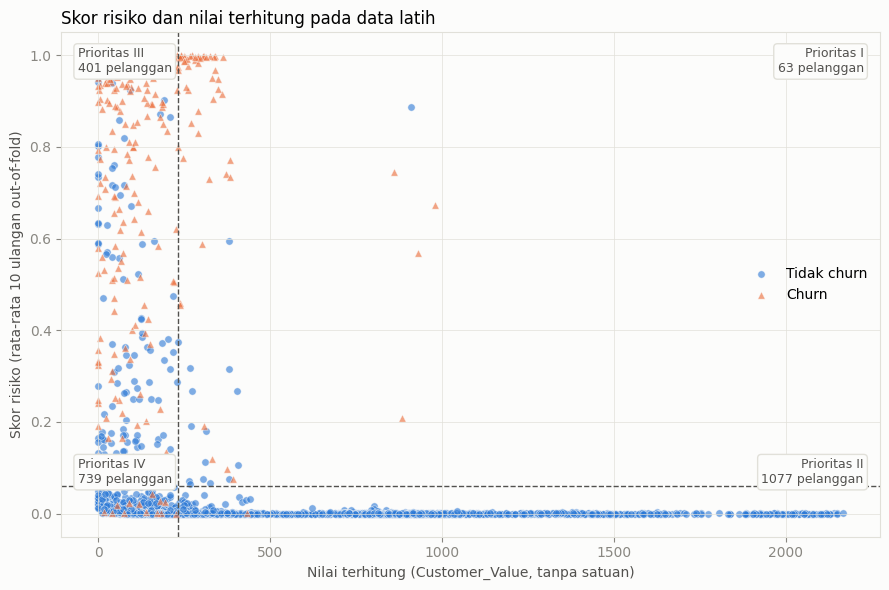

In [6]:
ink_secondary, ink_muted, grid_color = '#52514e', '#898781', '#e1e0d9'
colors = {0: '#2a78d6', 1: '#eb6834'}
markers = {0: 'o', 1: '^'}
labels = {0: 'Tidak churn', 1: 'Churn'}

fig, ax = plt.subplots(figsize=(9, 6), facecolor='#fcfcfb')
ax.set_facecolor('#fcfcfb')
for label in (0, 1):
    mask = y == label
    ax.scatter(value[mask], risk[mask], s=28, marker=markers[label], color=colors[label],
               alpha=0.6, edgecolors='#fcfcfb', linewidths=0.5, label=labels[label])
ax.axhline(RISK_THRESHOLD, color=ink_secondary, linewidth=1, linestyle='--')
ax.axvline(VALUE_CUTOFF, color=ink_secondary, linewidth=1, linestyle='--')

corner_text = {
    'Prioritas I': (0.98, 0.97, 'right', 'top'),
    'Prioritas III': (0.02, 0.97, 'left', 'top'),
    'Prioritas II': (0.98, 0.10, 'right', 'bottom'),
    'Prioritas IV': (0.02, 0.10, 'left', 'bottom'),
}
for name, (x, y_pos, ha, va) in corner_text.items():
    ax.text(x, y_pos, f"{name}\n{matrix.loc[name, 'Pelanggan']} pelanggan", transform=ax.transAxes,
            ha=ha, va=va, fontsize=9, color=ink_secondary,
            bbox={'facecolor': '#fcfcfb', 'edgecolor': grid_color, 'boxstyle': 'round,pad=0.3'}, zorder=5)

ax.set_xlabel('Nilai terhitung (Customer_Value, tanpa satuan)', color=ink_secondary)
ax.set_ylabel('Skor risiko (rata-rata 10 ulangan out-of-fold)', color=ink_secondary)
ax.set_title('Skor risiko dan nilai terhitung pada data latih', loc='left', fontsize=12)
ax.tick_params(colors=ink_muted)
for spine in ax.spines.values():
    spine.set_color(grid_color)
ax.grid(color=grid_color, linewidth=0.5)
ax.legend(loc='center right', frameon=False)
plt.tight_layout()
plt.show()

**Cara membaca grafik:** setiap titik adalah satu pelanggan di data latih. Garis putus-putus mendatar adalah threshold risiko 1:5, dan garis tegak adalah batas nilai median. Keempat sudut adalah keempat segmen. Segitiga oranye adalah pelanggan yang benar-benar churn, dan lingkaran biru yang tidak churn. Banyak titik bertumpuk di skor dekat 0, jadi tabel di atas lebih tepat untuk membaca jumlahnya. Sumbu tegak memakai rata-rata skor, sedangkan segmen memakai suara mayoritas, jadi beberapa titik yang sangat dekat dengan garis bisa termasuk segmen di seberangnya.

## 5. Pembanding: jika jumlah pelanggan yang bisa dihubungi terbatas

Segmen tidak mengurutkan pelanggan di dalamnya. Jika perusahaan hanya sanggup menghubungi sebagian kecil pelanggan, ada dua cara mengurutkan:

- **Urutan skor:** pelanggan dengan skor risiko tertinggi didahulukan.
- **Urutan skor × nilai:** pelanggan dengan hasil kali skor dan nilai terhitung tertinggi didahulukan.

Skor × nilai **hanya dipakai untuk mengurutkan**, bukan sebagai perkiraan kerugian, karena skor belum diuji sebagai peluang dan nilai bukan uang. Hasil di bawah adalah rata-rata 10 ulangan.

In [7]:
rows = []
for budget in BUDGETS:
    n_contact = int(round(budget * len(train)))
    for name, priority in (('Skor', lambda s: s), ('Skor × nilai', lambda s: s * value)):
        caught, value_caught = [], []
        for scores in oof_scores:
            chosen = np.argsort(-priority(scores), kind='stable')[:n_contact]
            churn_chosen = chosen[y[chosen] == 1]
            caught.append(len(churn_chosen))
            value_caught.append(value[churn_chosen].sum() / value[y == 1].sum())
        rows.append({
            'Dihubungi': f'{n_contact} ({budget:.0%})',
            'Urutan': name,
            'Churn tertangkap': round(np.mean(caught), 1),
            'Porsi nilai churn tertangkap': f'{np.mean(value_caught):.1%}',
        })
print(pd.DataFrame(rows).to_string(index=False))

Dihubungi       Urutan  Churn tertangkap Porsi nilai churn tertangkap
 114 (5%)         Skor             113.9                        33.6%
 114 (5%) Skor × nilai             107.5                        58.0%
228 (10%)         Skor             220.7                        60.0%
228 (10%) Skor × nilai             203.4                        81.3%
456 (20%)         Skor             334.7                        92.3%
456 (20%) Skor × nilai             300.0                        95.3%


**Cara membaca:** pada jumlah pelanggan yang sama, urutan skor × nilai biasanya mengumpulkan lebih banyak nilai terhitung dari pelanggan churn, tetapi menangkap lebih sedikit pelanggan churn. Tidak ada urutan yang selalu lebih baik. Pilihannya bergantung pada tujuan perusahaan: menahan sebanyak mungkin pelanggan, atau menahan nilai terhitung sebanyak mungkin.

## 6. Cek internal: dari mana pelanggan Prioritas I berasal

Audit Fase 1 menemukan pola berulang per 50 baris di file data. Pola ini dicatat sebagai **kelompok audit**, yaitu sisa bagi 50 dari posisi baris di file mentah. Pelanggan dalam satu kelompok audit cenderung sangat mirip. Kelompok audit tidak pernah dipakai sebagai fitur model, dan di sini hanya dipakai untuk memeriksa asal pelanggan di Prioritas I.

Kalau pelanggan Prioritas I tersebar di banyak kelompok, ciri segmen ini lebih mungkin berlaku umum. Kalau sebagian besar berasal dari sedikit kelompok, ciri segmen ini bisa lebih mencerminkan pola yang berulang di data.

In [8]:
group_churn_rate = pd.Series(y).groupby(audit_group).mean()
priority_mask = segment == 'Prioritas I'
origin = (
    pd.DataFrame({'Kelompok audit': audit_group[priority_mask], 'churn': y[priority_mask]})
    .groupby('Kelompok audit')
    .agg(Pelanggan=('churn', 'size'), Churn=('churn', 'sum'))
    .sort_values(['Pelanggan', 'Churn'], ascending=False)
)
origin['Porsi segmen'] = origin['Pelanggan'] / priority_mask.sum()
origin['Churn rate seluruh kelompok'] = group_churn_rate.loc[origin.index]

top3 = origin.head(3)
share_rows = top3['Pelanggan'].sum() / origin['Pelanggan'].sum()
share_churn = top3['Churn'].sum() / origin['Churn'].sum()
even_share = 1 / len(np.unique(audit_group))

shown = origin.copy()
for col in ('Porsi segmen', 'Churn rate seluruh kelompok'):
    shown[col] = (100 * shown[col]).round(1).astype(str) + '%'
print(shown.to_string())
print()
print(f'Prioritas I berisi {priority_mask.sum()} pelanggan dari {len(origin)} kelompok audit.')
print(f'3 kelompok teratas berisi {share_rows:.0%} pelanggan dan {share_churn:.1%} churn di segmen ini.')
print(f'Jika tersebar merata di 50 kelompok, tiap kelompok hanya menyumbang sekitar {even_share:.0%}.')

                Pelanggan  Churn Porsi segmen Churn rate seluruh kelompok
Kelompok audit                                                           
24                     27     24        42.9%                       54.2%
27                     11     11        17.5%                      100.0%
26                     10     10        15.9%                      100.0%
38                      5      4         7.9%                        8.3%
10                      3      0         4.8%                        0.0%
22                      2      2         3.2%                      100.0%
36                      2      2         3.2%                        6.7%
49                      1      1         1.6%                      100.0%
11                      1      0         1.6%                        0.0%
25                      1      0         1.6%                        0.0%

Prioritas I berisi 63 pelanggan dari 10 kelompok audit.
3 kelompok teratas berisi 76% pelanggan dan 83.3% churn

**Cara membaca:** dengan asumsi tiap baris adalah satu pelanggan (keputusan 1), Prioritas I tetap berisi pelanggan yang berbeda. Namun, sebagian besar dari mereka berasal dari sedikit kelompok audit dengan pola yang sangat mirip. Jadi ciri Prioritas I bisa lebih mencerminkan pola berulang di data daripada pelanggan pada umumnya, dan segmen ini perlu dibaca hati-hati.

## 7. Kepekaan terhadap rasio

Rasio biaya bisa dipilih pengguna (keputusan 32). Tabel ini menunjukkan ukuran keempat segmen jika threshold rasio lain yang dipakai, dengan aturan suara mayoritas yang sama. Batas nilai tetap median.

In [9]:
rows = []
for ratio, row in thresholds.iterrows():
    counts = pd.Series(assign_segment(high_risk_by_vote(row['threshold']))).value_counts()
    rows.append({'Rasio': ratio, 'Threshold': row['threshold'], **{name: counts.get(name, 0) for name in SEGMENTS}})
sensitivity = pd.DataFrame(rows).set_index('Rasio')
assert (sensitivity[SEGMENTS].sum(axis=1) == len(train)).all()
print(sensitivity.to_string())

       Threshold  Prioritas I  Prioritas II  Prioritas III  Prioritas IV
Rasio                                                                   
1:2        0.230           52          1088            330           810
1:5        0.060           63          1077            401           739
1:10       0.045           66          1074            416           724


**Cara membaca:** threshold yang lebih rendah membuat lebih banyak pelanggan masuk risiko tinggi, sehingga Prioritas I dan III membesar. Jika ukurannya hanya berubah sedikit, pilihan rasio tidak banyak mengubah segmen.

## Cara membaca hasil

**Ringkasnya:**

- Pelanggan berisiko tinggi umumnya bernilai terhitung rendah, jadi segmen Prioritas I berukuran kecil.
- Matriks membantu membagi pelanggan ke empat kelompok tindakan. Urutan skor × nilai memberi cara lain jika jumlah pelanggan yang bisa dihubungi terbatas, dengan untung rugi yang terlihat di bagian 5.

**Keterbatasan:**

1. **`Customer_Value` bukan uang.** Rumus dan satuannya tidak diketahui, jadi hasil ini tidak boleh dibaca sebagai kerugian atau penghematan uang.
2. **Nilai berasal dari 9 bulan pertama.** Nilai rendah pada pelanggan churn mungkin sudah mencerminkan aktivitas yang menurun, jadi belum tentu menggambarkan nilai mereka ke depan.
3. **`Customer_Value` juga fitur model.** Skor risiko sudah memakai kolom ini, jadi risiko dan nilai bukan dua ukuran yang sepenuhnya terpisah.
4. **Prioritas I kecil dan terpusat.** Sebagian besar pelanggannya berasal dari sedikit kelompok audit, jadi cirinya belum tentu berlaku umum.
5. **Skor belum diuji sebagai peluang.** Skor dipakai untuk membagi dan mengurutkan, bukan sebagai peluang churn yang pasti.
6. **Tindakan adalah hipotesis.** Segmen menunjukkan asosiasi, dan tidak membuktikan bahwa menghubungi pelanggan akan mencegah churn.
7. **Bukan performa pada pelanggan baru.** Semua angka berasal dari data latih dengan CV acak.